# XGBoost et prédiction conforme —Analyse de Fitness Club

## 1. Import + générer/récupérer le découpage

In [1]:
import time
import tempfile
import contextlib
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from generation_decoupage import generation_decoupage

plt.rcParams["figure.figsize"] = (7, 4)

dossier = Path.cwd()

# Graine du découpage
GRAINE = 90 #<--------------------------------

decoupage = generation_decoupage(
    fichier_csv=dossier / "fitness_club_modifie.csv",
    graine=GRAINE,
    colonne_cible="attended",
)

#variables
donnees = decoupage["donnees_decoupage"]
fichier_decoupage = decoupage["fichier_decoupage"]
X_D = decoupage["X_D"]
X_test = decoupage["X_test"]
y_D = decoupage["y_D"]
y_test = decoupage["y_test"]
X_train = decoupage["X_train"]
X_cal = decoupage["X_cal"]
y_train = decoupage["y_train"]
y_cal = decoupage["y_cal"]
classes = decoupage["classes"]

#affichage
X = donnees.drop(columns=["attended", "TRAIN_TEST", "SPLIT_CONFORMAL"])
y = donnees["attended"]

print("Dimensions du CSV découpé :", donnees.shape)
print("Variables explicatives :", X.shape[1])
print("Classes de la cible :", list(classes))


Découpage créé : /Users/elias/Documents/Courses/5A/PIR/Projet_RI_TabFn/decoupage_90.csv
Graine : 90
Groupe D : 1124 lignes | Test final : 375 lignes
Entraînement : 786 lignes | Calibration : 338 lignes
Dimensions du CSV découpé : (1499, 21)
Variables explicatives : 18
Classes de la cible : ['No', 'Yes']


## 2. Vérifications datas

In [2]:
display(X.head())
print("\nTypes des colonnes :")
print(X.dtypes)
print("\nValeurs manquantes :")
print(X.isna().sum()[X.isna().sum() > 0])
print("\nRépartition de la cible :")
print(y.value_counts(normalize=True).round(3))

,months_as_member,weight,days_before,day_of_week_Fri,day_of_week_Mon,day_of_week_Sat,day_of_week_Sun,day_of_week_Thu,day_of_week_Tue,day_of_week_Wed,time_AM,time_PM,category_-,category_Aqua,category_Cycling,category_HIIT,category_Strength,category_Yoga
0,15,65.47,6,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0
1,18,77.85,8,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0
2,13,67.26,10,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0
3,7,86.70,12,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0
4,5,135.18,8,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0



Types des colonnes :
months_as_member       int64
weight               float64
days_before            int64
day_of_week_Fri        int64
day_of_week_Mon        int64
day_of_week_Sat        int64
day_of_week_Sun        int64
day_of_week_Thu        int64
day_of_week_Tue        int64
day_of_week_Wed        int64
time_AM                int64
time_PM                int64
category_-             int64
category_Aqua          int64
category_Cycling       int64
category_HIIT          int64
category_Strength      int64
category_Yoga          int64
dtype: object

Valeurs manquantes :
weight    19
dtype: int64

Répartition de la cible :
attended
No     0.697
Yes    0.303
Name: proportion, dtype: float64


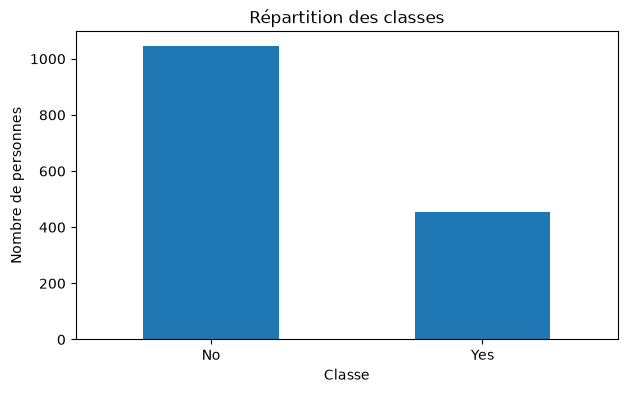

In [3]:
y.value_counts().plot(kind="bar", rot=0)
plt.title("Répartition des classes")
plt.xlabel("Classe")
plt.ylabel("Nombre de personnes")
plt.show()

## 3. Entraîner XGBoost


In [4]:
modele = XGBClassifier(
    n_estimators=200,     # nombre d'arbres
    max_depth=4,           # profondeur des arbres
    learning_rate=0.1,     # vitesse d'apprentissage
    n_jobs=1,
    random_state=0,
    tree_method="hist"
)

debut = time.time()
modele.fit(X_D, y_D)
probabilites_test = modele.predict_proba(X_test)
print("Temps d'entraînement et de prédiction :", round(time.time() - debut, 2), "secondes")

Temps d'entraînement et de prédiction : 0.02 secondes


In [5]:
# Chaque ligne contient la probabilité prédite pour chaque classe.
display(pd.DataFrame(
    probabilites_test[:5],
    columns=[f"P({nom})" for nom in classes]
).round(3))

def metriques_point(y_vrai, proba):
    # Accuracy + précision / rappel / F1 en moyenne macro (les deux classes comptent autant).
    pred = proba.argmax(axis=1)
    return {
        "accuracy": accuracy_score(y_vrai, pred),
        "precision_macro": precision_score(y_vrai, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_vrai, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_vrai, pred, average="macro", zero_division=0),
    }

print(pd.Series(metriques_point(y_test, probabilites_test)).round(3))
print("Classe majoritaire:",
      round(max(np.mean(y_test), 1 - np.mean(y_test)), 3))

,P(No),P(Yes)
0,0.073,0.927
1,0.996,0.004
2,0.892,0.108
3,0.879,0.121
4,0.978,0.022


accuracy           0.763
precision_macro    0.720
recall_macro       0.694
f1_macro           0.703
dtype: float64
Classe majoritaire: 0.696


## 4. Split conformal

On recupere le train D et ses 2 modalités :
- **entraînement** : 0;
- **calibration** : 1 (calcul seuil de confiance)

In [6]:
debut = time.time()
modele_split = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.1,
    n_jobs=1, random_state=0, tree_method="hist"
)
modele_split.fit(X_train, y_train)

proba_cal = modele_split.predict_proba(X_cal)
proba_test_split = modele_split.predict_proba(X_test)
TEMPS_SPLIT = time.time() - debut

print("Entraînement :", X_train.shape)
print("Calibration :", X_cal.shape)
print("Test final :", X_test.shape)
print("Temps split :", round(TEMPS_SPLIT, 2), "secondes")

Entraînement : (786, 18)
Calibration : (338, 18)
Test final : (375, 18)
Temps split : 0.01 secondes


La fonction ci-dessous calcule le seuil à partir des données de calibration, puis garde pour chaque personne les classes dont la probabilité est assez élevée.

In [7]:
def split_conformal(proba_cal, y_cal, proba_test, alpha):
    # Score de la vraie classe pour chaque personne de calibration.
    n = len(y_cal)
    scores = 1 - proba_cal[np.arange(n), y_cal]

    # Seuil de calibration (quantile corrigé pour la taille de l'échantillon).
    rang = int(np.ceil((n + 1) * (1 - alpha)))
    rang = min(rang, n)
    seuil = np.sort(scores)[rang - 1]

    # Une classe est gardée si sa probabilité est suffisante.
    ensembles = proba_test >= 1 - seuil
    return ensembles


def mesurer_ensembles(ensembles, vraies_classes):
    tailles = ensembles.sum(axis=1)
    couverture = ensembles[np.arange(len(vraies_classes)), vraies_classes].mean()

    return {
        "coverage": couverture,
        "avg_set_size": tailles.mean(),
        "singleton_rate": (tailles == 1).mean(),
        "empty_rate": (tailles == 0).mean()
    }

In [8]:
alpha = 0.1
ensembles_split = split_conformal(proba_cal, y_cal, proba_test_split, alpha)
resultat = mesurer_ensembles(ensembles_split, y_test)

print("Couverture visée :", 1 - alpha)
print(pd.Series(resultat).round(3))

Couverture visée : 0.9
coverage          0.904
avg_set_size      1.384
singleton_rate    0.616
empty_rate        0.000
dtype: float64


`coverage` : >0.9, c'est bon
- `avg_set_size` : plutot proche de 1 ce n'est pas optimal
- `singleton_rate` : 61.6% des ensembles ne contiennent qu'une classe, le reste est indécis

### Split sur plusieurs graines

Une seule graine = un seul tirage du test (375 personnes) et de la calibration (338) : la couverture bouge d'environ ±2 points d'un tirage à l'autre. On refait donc le split conformal sur les graines 0, 1, 2, 3, 90 et on donne la moyenne ± l'écart-type. Les fichiers `decoupage_<graine>.csv` sont écrits dans un dossier temporaire pour ne pas encombrer le dépôt.

In [9]:
GRAINES = [0, 1, 2, 3, 90]
alphas = [0.05, 0.1, 0.2]
dossier_tmp = tempfile.mkdtemp()

decoupages = {}
for g in GRAINES:
    with contextlib.redirect_stdout(io.StringIO()):  # on cache les messages de generation_decoupage
        decoupages[g] = generation_decoupage(
            fichier_csv=dossier / "fitness_club_modifie.csv",
            graine=g, colonne_cible="attended", dossier_sortie=dossier_tmp,
        )

lignes_split = []
for g, d in decoupages.items():
    debut = time.time()
    m = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                      n_jobs=1, random_state=0, tree_method="hist")
    m.fit(d["X_train"], d["y_train"])
    p_cal = m.predict_proba(d["X_cal"])
    p_test = m.predict_proba(d["X_test"])
    t = time.time() - debut
    for alpha in alphas:
        ensembles = split_conformal(p_cal, d["y_cal"], p_test, alpha)
        lignes_split.append({"graine": g, "methode": "Split", "alpha": alpha,
                             **mesurer_ensembles(ensembles, d["y_test"]),
                             **metriques_point(d["y_test"], p_test), "temps_s": t})

multi_split = pd.DataFrame(lignes_split)
display(multi_split.pivot(index="graine", columns="alpha", values="coverage").round(3))
display(multi_split.groupby("alpha")[["coverage", "avg_set_size", "singleton_rate", "accuracy", "f1_macro"]]
        .agg(["mean", "std"]).round(3))

alpha,0.05,0.10,0.20
graine,,,
0,0.957,0.904,0.795
1,0.944,0.875,0.776
2,0.944,0.893,0.773
3,0.963,0.931,0.856
90,0.949,0.904,0.805


coverage        avg_set_size        singleton_rate        accuracy  \
          mean    std         mean    std           mean    std     mean   
alpha                                                                      
0.05     0.951  0.008        1.549  0.043          0.451  0.043    0.758   
0.10     0.901  0.020        1.375  0.056          0.625  0.056    0.758   
0.20     0.801  0.033        1.105  0.061          0.895  0.061    0.758   

             f1_macro         
         std     mean    std  
alpha                         
0.05   0.017    0.698  0.026  
0.10   0.017    0.698  0.026  
0.20   0.017    0.698  0.026

## 5. Jackknife+ et CV+

Def rappel:
**Jackknife+** : on entraîne un modèle en retirant une seule ligne, et on recommence pour chaque ligne.
**CV+** : folds


In [10]:
def entrainer_et_predire(X_apprentissage, y_apprentissage, X_a_predire):
    modele = XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.1,
        n_jobs=1, random_state=0, tree_method="hist"
    )
    modele.fit(X_apprentissage, y_apprentissage)
    return modele.predict_proba(X_a_predire)


def calculer_scores_plus(X, y, X_test, methode="jackknife", nombre_folds=10):
    n = len(y)
    scores_vrais = np.zeros(n)
    scores_test = None

    if methode == "jackknife":
        # Chaque ligne est retirée à tour de rôle.
        groupes = [(np.delete(np.arange(n), i), np.array([i])) for i in range(n)]
    else:
        # CV+ : on retire un groupe à la fois.
        cv = StratifiedKFold(n_splits=nombre_folds, shuffle=True, random_state=0)
        groupes = list(cv.split(X, y))

    for train_ids, val_ids in groupes:
        X_a_predire = np.vstack([X[val_ids], X_test])
        probas = entrainer_et_predire(X[train_ids], y[train_ids], X_a_predire)

        # Score des lignes qui ont été laissées de côté.
        probas_val = probas[:len(val_ids)]
        scores_vrais[val_ids] = 1 - probas_val[np.arange(len(val_ids)), y[val_ids]]

        # Scores des classes proposées pour le test.
        probas_test_plus = probas[len(val_ids):]
        if scores_test is None:
            scores_test = np.zeros((n, len(X_test), probas_test_plus.shape[1]))
        scores_test[val_ids] = 1 - probas_test_plus

    return scores_vrais, scores_test


def construire_ensembles_plus(scores_vrais, scores_test, alpha):
    # On compte combien de modèles jugent chaque classe moins plausible.
    nombre_rejets = (scores_test > scores_vrais[:, None, None]).sum(axis=0)
    return nombre_rejets < (1 - alpha) * (len(scores_vrais) + 1)


def proba_moyenne_plus(scores_test):
    # Prédiction ponctuelle pour CV+/Jackknife+ : moyenne des probas des modèles leave-out.
    return (1 - scores_test).mean(axis=0)

### CV+ 

In [11]:
debut = time.time()
scores_cv, predictions_cv = calculer_scores_plus(
    X_D, y_D, X_test, methode="cv", nombre_folds=10
)
TEMPS_CV = time.time() - debut
print("Temps CV+ :", round(TEMPS_CV, 1), "secondes")

for alpha in [0.05, 0.1, 0.2]:
    ensembles = construire_ensembles_plus(scores_cv, predictions_cv, alpha)
    print("alpha =", alpha, mesurer_ensembles(ensembles, y_test))

Temps CV+ : 0.1 secondes
alpha = 0.05 {'coverage': np.float64(0.9706666666666667), 'avg_set_size': np.float64(1.5946666666666667), 'singleton_rate': np.float64(0.4053333333333333), 'empty_rate': np.float64(0.0)}
alpha = 0.1 {'coverage': np.float64(0.9253333333333333), 'avg_set_size': np.float64(1.408), 'singleton_rate': np.float64(0.592), 'empty_rate': np.float64(0.0)}
alpha = 0.2 {'coverage': np.float64(0.8133333333333334), 'avg_set_size': np.float64(1.0986666666666667), 'singleton_rate': np.float64(0.9013333333333333), 'empty_rate': np.float64(0.0)}


alpha=0.05: avg_set_size=1.6 c'est moyen mais on veut quelque chose de très précis, singleton rate <0.5
alpha=0.2: avg_set_size proche de 1 (1.09) c'est top; singleton rate de 0.901 top aussi mais on est moins précis au départ

### CV+ sur plusieurs graines

Mêmes graines que pour le split (les folds de CV+ restent tirés avec `random_state=0`).

In [12]:
lignes_cv = []
for g, d in decoupages.items():
    debut = time.time()
    s_cv, pr_cv = calculer_scores_plus(d["X_D"], d["y_D"], d["X_test"], methode="cv", nombre_folds=10)
    t = time.time() - debut
    m_cv = metriques_point(d["y_test"], proba_moyenne_plus(pr_cv))
    for alpha in alphas:
        ensembles = construire_ensembles_plus(s_cv, pr_cv, alpha)
        lignes_cv.append({"graine": g, "methode": "CV+", "alpha": alpha,
                          **mesurer_ensembles(ensembles, d["y_test"]), **m_cv, "temps_s": t})

multi_cv = pd.DataFrame(lignes_cv)
display(multi_cv.pivot(index="graine", columns="alpha", values="coverage").round(3))
display(multi_cv.groupby("alpha")[["coverage", "avg_set_size", "singleton_rate", "accuracy", "f1_macro"]]
        .agg(["mean", "std"]).round(3))

alpha,0.05,0.10,0.20
graine,,,
0,0.971,0.925,0.797
1,0.957,0.907,0.808
2,0.952,0.909,0.808
3,0.971,0.936,0.880
90,0.971,0.925,0.813


coverage        avg_set_size        singleton_rate        accuracy  \
          mean    std         mean    std           mean    std     mean   
alpha                                                                      
0.05     0.964  0.009        1.588  0.023          0.412  0.023    0.769   
0.10     0.921  0.012        1.398  0.037          0.602  0.037    0.769   
0.20     0.821  0.033        1.119  0.042          0.881  0.042    0.769   

             f1_macro         
         std     mean    std  
alpha                         
0.05   0.024    0.708  0.035  
0.10   0.024    0.708  0.035  
0.20   0.024    0.708  0.035

### Lancer Jackknife+ CHANGER TRUE/FALSE parce que c'est bien long sinon


In [13]:
# Mettre True pour lancer Jackknife+, False pour le passer.
LANCER_JACKKNIFE = True

if LANCER_JACKKNIFE:
    debut = time.time()
    scores_jk, predictions_jk = calculer_scores_plus(
        X_D, y_D, X_test, methode="jackknife"
    )
    TEMPS_JK = time.time() - debut
    print("Temps Jackknife+ :", round(TEMPS_JK, 1), "secondes")

    for alpha in [0.05, 0.1, 0.2]:
        ensembles = construire_ensembles_plus(scores_jk, predictions_jk, alpha)
        print("alpha =", alpha, mesurer_ensembles(ensembles, y_test))
else:
    print("jackknife ne s'est pas lancé: change FALSE en TRUE si tu le souhaites")

Temps Jackknife+ : 13.2 secondes
alpha = 0.05 {'coverage': np.float64(0.96), 'avg_set_size': np.float64(1.5866666666666667), 'singleton_rate': np.float64(0.41333333333333333), 'empty_rate': np.float64(0.0)}
alpha = 0.1 {'coverage': np.float64(0.9066666666666666), 'avg_set_size': np.float64(1.3973333333333333), 'singleton_rate': np.float64(0.6026666666666667), 'empty_rate': np.float64(0.0)}
alpha = 0.2 {'coverage': np.float64(0.7946666666666666), 'avg_set_size': np.float64(1.0773333333333333), 'singleton_rate': np.float64(0.9226666666666666), 'empty_rate': np.float64(0.0)}


## 6. Comparer les méthodes

On compare la couverture et la taille moyenne des ensembles pour plusieurs valeurs de `alpha`, plus les métriques ponctuelles (accuracy, précision / rappel / F1 macro) et le temps de chaque méthode.

Prédiction ponctuelle : Split = modèle entraîné sur la partie entraînement ; CV+ / Jackknife+ = moyenne des probas des modèles leave-out.

La graine du découpage est définie par `GRAINE` dans la section 1. Le fichier `decoupage_<graine>.csv` permet de retrouver exactement les mêmes groupes lors d'une nouvelle exécution avec le même CSV source.

In [14]:
alphas = [0.05, 0.1, 0.2]
comparaison = []

for alpha in alphas:
    ensembles = split_conformal(proba_cal, y_cal, proba_test_split, alpha)
    mesures = mesurer_ensembles(ensembles, y_test)
    comparaison.append({"methode": "Split", "alpha": alpha, **mesures})

    ensembles = construire_ensembles_plus(scores_cv, predictions_cv, alpha)
    mesures = mesurer_ensembles(ensembles, y_test)
    comparaison.append({"methode": "CV+", "alpha": alpha, **mesures})

    if LANCER_JACKKNIFE:
        ensembles = construire_ensembles_plus(scores_jk, predictions_jk, alpha)
        mesures = mesurer_ensembles(ensembles, y_test)
        comparaison.append({"methode": "Jackknife+", "alpha": alpha, **mesures})

point = {
    "Split": (metriques_point(y_test, proba_test_split), TEMPS_SPLIT),
    "CV+": (metriques_point(y_test, proba_moyenne_plus(predictions_cv)), TEMPS_CV),
}
if LANCER_JACKKNIFE:
    point["Jackknife+"] = (metriques_point(y_test, proba_moyenne_plus(predictions_jk)), TEMPS_JK)
for ligne in comparaison:
    m, t = point[ligne["methode"]]
    ligne.update(m)
    ligne["temps_s"] = t

resultats = pd.DataFrame(comparaison)
display(resultats.round(3))

,methode,alpha,coverage,avg_set_size,singleton_rate,empty_rate,accuracy,precision_macro,recall_macro,f1_macro,temps_s
0,Split,0.05,0.949,1.571,0.429,0.0,0.763,0.721,0.686,0.698,0.011
1,CV+,0.05,0.971,1.595,0.405,0.0,0.765,0.724,0.693,0.704,0.119
2,Jackknife+,0.05,0.960,1.587,0.413,0.0,0.771,0.731,0.699,0.710,13.220
3,Split,0.10,0.904,1.384,0.616,0.0,0.763,0.721,0.686,0.698,0.011
4,CV+,0.10,0.925,1.408,0.592,0.0,0.765,0.724,0.693,0.704,0.119
5,Jackknife+,0.10,0.907,1.397,0.603,0.0,0.771,0.731,0.699,0.710,13.220
6,Split,0.20,0.805,1.115,0.885,0.0,0.763,0.721,0.686,0.698,0.011
7,CV+,0.20,0.813,1.099,0.901,0.0,0.765,0.724,0.693,0.704,0.119
8,Jackknife+,0.20,0.795,1.077,0.923,0.0,0.771,0.731,0.699,0.710,13.220


resultats bizarre, sur cette graine le split est meilleur que jackknife et cv

## 7. Sauvegarde des résultats

`results_xgboost.csv` : tableau de la section 6 (graine 90, `source = principal`) + les lignes des boucles multi-graines (`source = multi_graines`). Ce fichier est lu par `comparaison.ipynb` : après une modification, relancer ce notebook puis `comparaison.ipynb`.

In [15]:
sortie = pd.concat([
    resultats.assign(graine=GRAINE, source="principal"),
    multi_split.assign(source="multi_graines"),
    multi_cv.assign(source="multi_graines"),
], ignore_index=True)
sortie.insert(0, "modele", "XGBoost")
sortie.to_csv(dossier / "results_xgboost.csv", index=False)
print("Écrit :", dossier / "results_xgboost.csv", sortie.shape)

Écrit : /Users/elias/Documents/Courses/5A/PIR/Projet_RI_TabFn/results_xgboost.csv (39, 14)
